   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
Dataset Shape: (20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-nul

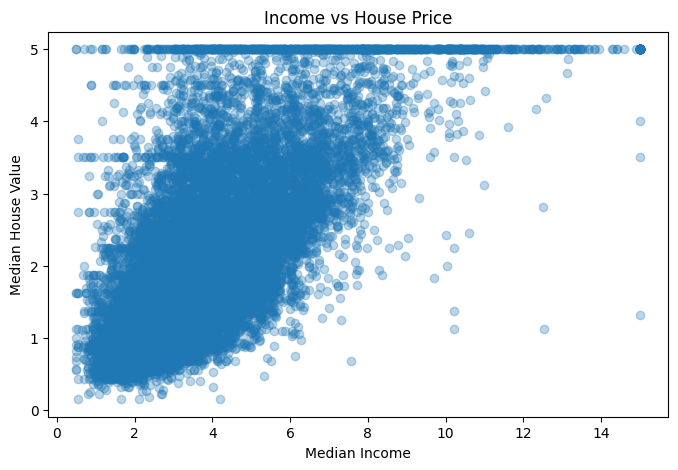

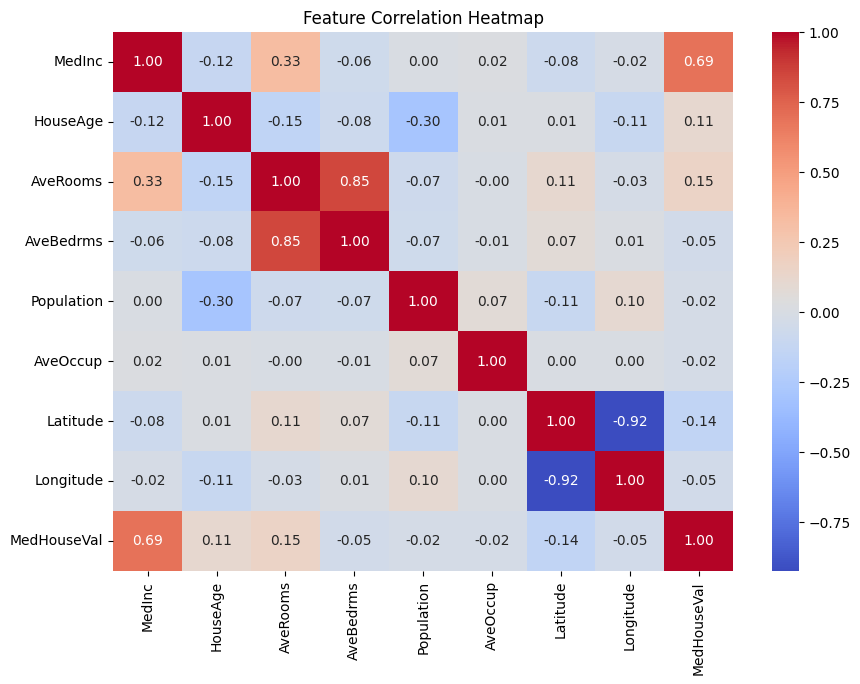

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64
Model Training Completed!
   Actual Price  Predicted Price
0       0.47700         0.719123
1       0.45800         1.764017
2       5.00001         2.709659
3       2.18600         2.838926
4       2.78000         2.604657
5       1.58700         2.011754
6       1.98200         2.645500
7       1.57500         2.168755
8       3.40000         2.740746
9       

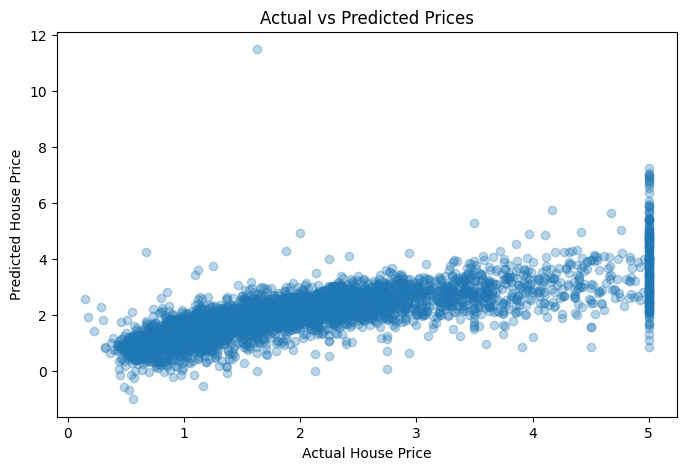

      Feature  Coefficient  Absolute Coefficient
3   AveBedrms     0.783145              0.783145
0      MedInc     0.448675              0.448675
7   Longitude    -0.433708              0.433708
6    Latitude    -0.419792              0.419792
2    AveRooms    -0.123323              0.123323
1    HouseAge     0.009724              0.009724
5    AveOccup    -0.003526              0.003526
4  Population    -0.000002              0.000002
Predicted Value: 2.5155372707434083
Estimated House Value ($): 251553.72707434083


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing



housing = fetch_california_housing(as_frame=True)
df = housing.frame

print(df.head())
print("Dataset Shape:", df.shape)



print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())



plt.figure(figsize=(8,5))
plt.scatter(df["MedInc"], df["MedHouseVal"], alpha=0.3)
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Income vs House Price")
plt.show()



plt.figure(figsize=(10,7))
sns.heatmap(df.corr(), annot=True,
            cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print(X.head())
print(y.head())


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Model Training Completed!")



predictions = model.predict(X_test)

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": predictions
})

print(results.head(10))




from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)



plt.figure(figsize=(8,5))
plt.scatter(y_test, predictions, alpha=0.3)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted Prices")

plt.show()




coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.named_steps["regressor"].coef_
})

coefficients["Absolute Coefficient"] = \
    coefficients["Coefficient"].abs()

print(
    coefficients.sort_values(
        by="Absolute Coefficient",
        ascending=False
    )
)





new_house = pd.DataFrame([{
    "MedInc": 5.0,
    "HouseAge": 20.0,
    "AveRooms": 6.0,
    "AveBedrms": 1.1,
    "Population": 1000.0,
    "AveOccup": 3.0,
    "Latitude": 34.05,
    "Longitude": -118.25
}])

predicted_value = model.predict(new_house)[0]
predicted_dollars = predicted_value * 100000

print("Predicted Value:", predicted_value)
print("Estimated House Value ($):", predicted_dollars)
